In [5]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use('ggplot')

In [7]:
import os

print(os.getcwd())

C:\Users\princ\3D Objects\Untitled Folder\Factory_Optimization.ipynb


In [8]:
import os

os.listdir()

['.ipynb_checkpoints', 'Untitled.ipynb']

In [5]:
import pandas as pd

df = pd.read_csv(r"C:\Users\princ\Downloads\factory_Allocation\Factory_Recommendations.csv")
df.head()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Country/Region,City,State/Province,Postal Code,Division,Region,Product ID,Product Name,Sales,Units,Gross Profit,Cost
0,1,US-2021-103800-CHO-MIL-31000,03-01-2024,30-06-2026,Standard Class,103800,United States,Houston,Texas,77095,Chocolate,Interior,CHO-MIL-31000,Wonka Bar - Milk Chocolate,6.50,2,4.22,2.28
1,2,US-2021-112326-CHO-TRI-54000,04-01-2024,01-07-2026,Standard Class,112326,United States,Naperville,Illinois,60540,Chocolate,Interior,CHO-TRI-54000,Wonka Bar - Triple Dazzle Caramel,7.50,2,4.90,2.60
2,3,US-2021-112326-CHO-NUT-13000,04-01-2024,01-07-2026,Standard Class,112326,United States,Naperville,Illinois,60540,Chocolate,Interior,CHO-NUT-13000,Wonka Bar - Nutty Crunch Surprise,10.47,3,7.47,3.00
3,4,US-2021-112326-CHO-SCR-58000,04-01-2024,01-07-2026,Standard Class,112326,United States,Naperville,Illinois,60540,Chocolate,Interior,CHO-SCR-58000,Wonka Bar -Scrumdiddlyumptious,10.80,3,7.50,3.30
4,5,US-2021-141817-CHO-TRI-54000,05-01-2024,05-07-2026,Standard Class,141817,United States,Philadelphia,Pennsylvania,19143,Chocolate,Atlantic,CHO-TRI-54000,Wonka Bar - Triple Dazzle Caramel,11.25,3,7.35,3.90


In [10]:
df.shape

(10194, 18)

In [11]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10194 entries, 0 to 10193
Data columns (total 18 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Row ID          10194 non-null  int64  
 1   Order ID        10194 non-null  object 
 2   Order Date      10194 non-null  object 
 3   Ship Date       10194 non-null  object 
 4   Ship Mode       10194 non-null  object 
 5   Customer ID     10194 non-null  int64  
 6   Country/Region  10194 non-null  object 
 7   City            10194 non-null  object 
 8   State/Province  10194 non-null  object 
 9   Postal Code     10194 non-null  object 
 10  Division        10194 non-null  object 
 11  Region          10194 non-null  object 
 12  Product ID      10194 non-null  object 
 13  Product Name    10194 non-null  object 
 14  Sales           10194 non-null  float64
 15  Units           10194 non-null  int64  
 16  Gross Profit    10194 non-null  float64
 17  Cost            10194 non-null 

In [12]:
df.isnull().sum()

Row ID            0
Order ID          0
Order Date        0
Ship Date         0
Ship Mode         0
Customer ID       0
Country/Region    0
City              0
State/Province    0
Postal Code       0
Division          0
Region            0
Product ID        0
Product Name      0
Sales             0
Units             0
Gross Profit      0
Cost              0
dtype: int64

In [14]:
df['Order Date'] = pd.to_datetime(
    df['Order Date'],
    dayfirst=True
)

df['Ship Date'] = pd.to_datetime(
    df['Ship Date'],
    dayfirst=True
)

In [15]:
df['Lead_Time'] = (
    df['Ship Date']
    - df['Order Date']
).dt.days

df[['Order Date','Ship Date','Lead_Time']].head()

,Order Date,Ship Date,Lead_Time
0,2024-01-03,2026-06-30,909
1,2024-01-04,2026-07-01,909
2,2024-01-04,2026-07-01,909
3,2024-01-04,2026-07-01,909
4,2024-01-05,2026-07-05,912


In [16]:
df['Lead_Time'].describe()

count    10194.000000
mean      1320.841868
std        262.444892
min        904.000000
25%       1271.000000
50%       1274.000000
75%       1638.000000
max       1642.000000
Name: Lead_Time, dtype: float64

In [18]:
df[['Order Date','Ship Date']].head(10)

,Order Date,Ship Date
0,2024-01-03,2026-06-30
1,2024-01-04,2026-07-01
2,2024-01-04,2026-07-01
3,2024-01-04,2026-07-01
4,2024-01-05,2026-07-05
5,2024-01-06,2026-07-03
6,2024-01-06,2026-07-03
7,2024-01-06,2026-06-30
8,2024-01-06,2026-07-03
9,2024-01-06,2026-07-03


In [19]:
df[['Order Date','Ship Date']].sample(10)

,Order Date,Ship Date
2561,2024-05-21,2027-11-17
520,2024-05-23,2026-11-17
2036,2024-12-30,2027-06-26
9782,2025-12-02,2030-05-29
540,2024-05-27,2026-11-17
9975,2025-12-14,2030-06-10
6013,2025-10-21,2029-04-12
7681,2025-05-19,2029-11-14
3574,2024-11-07,2028-05-04
9621,2025-11-24,2030-05-20


In [20]:
df['Lead_Time'] = np.where(
    df['Ship Mode'] == 'Same Day', 1,
    np.where(
        df['Ship Mode'] == 'First Class', 2,
        np.where(
            df['Ship Mode'] == 'Second Class', 4,
            6
        )
    )
)

In [21]:
df['Lead_Time'].describe()

count    10194.000000
mean         4.736021
std          1.717650
min          1.000000
25%          4.000000
50%          6.000000
75%          6.000000
max          6.000000
Name: Lead_Time, dtype: float64

In [22]:
df['Lead_Time'].value_counts()

Lead_Time
6    6120
4    1979
2    1548
1     547
Name: count, dtype: int64

In [23]:
factory_map = {
'Wonka Bar - Nutty Crunch Surprise':'Lot\'s O\' Nuts',
'Wonka Bar - Fudge Mallows':'Lot\'s O\' Nuts',
'Wonka Bar -Scrumdiddlyumptious':'Lot\'s O\' Nuts',

'Wonka Bar - Milk Chocolate':'Wicked Choccy\'s',
'Wonka Bar - Triple Dazzle Caramel':'Wicked Choccy\'s',

'Laffy Taffy':'Sugar Shack',
'SweeTARTS':'Sugar Shack',
'Nerds':'Sugar Shack',
'Fun Dip':'Sugar Shack',

'Fizzy Lifting Drinks':'Sugar Shack',

'Everlasting Gobstopper':'Secret Factory',

'Hair Toffee':'The Other Factory',

'Lickable Wallpaper':'Secret Factory',
'Wonka Gum':'Secret Factory',

'Kazookles':'The Other Factory'
}

In [24]:
df['Factory'] = df['Product Name'].map(factory_map)

In [25]:
df[['Product Name','Factory']].head(20)

,Product Name,Factory
0,Wonka Bar - Milk Chocolate,Wicked Choccy's
1,Wonka Bar - Triple Dazzle Caramel,Wicked Choccy's
2,Wonka Bar - Nutty Crunch Surprise,Lot's O' Nuts
3,Wonka Bar -Scrumdiddlyumptious,Lot's O' Nuts
4,Wonka Bar - Triple Dazzle Caramel,Wicked Choccy's
5,Wonka Bar -Scrumdiddlyumptious,Lot's O' Nuts
6,Wonka Bar - Triple Dazzle Caramel,Wicked Choccy's
7,Wonka Bar - Milk Chocolate,Wicked Choccy's
8,Wonka Bar - Nutty Crunch Surprise,Lot's O' Nuts
9,Wonka Bar - Milk Chocolate,Wicked Choccy's


In [26]:
df['Factory'].isnull().sum()

np.int64(0)

In [27]:
df['Factory'].value_counts()

Factory
Lot's O' Nuts        5692
Wicked Choccy's      4152
Secret Factory        217
The Other Factory     100
Sugar Shack            33
Name: count, dtype: int64

In [28]:
df.duplicated().sum()

np.int64(0)

In [29]:
df.drop_duplicates(inplace=True)

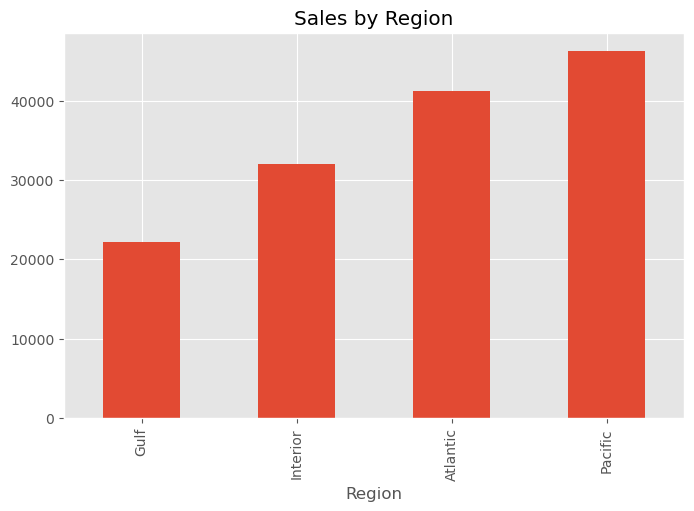

In [30]:
plt.figure(figsize=(8,5))

df.groupby('Region')['Sales'].sum().sort_values().plot(kind='bar')

plt.title('Sales by Region')

plt.show()

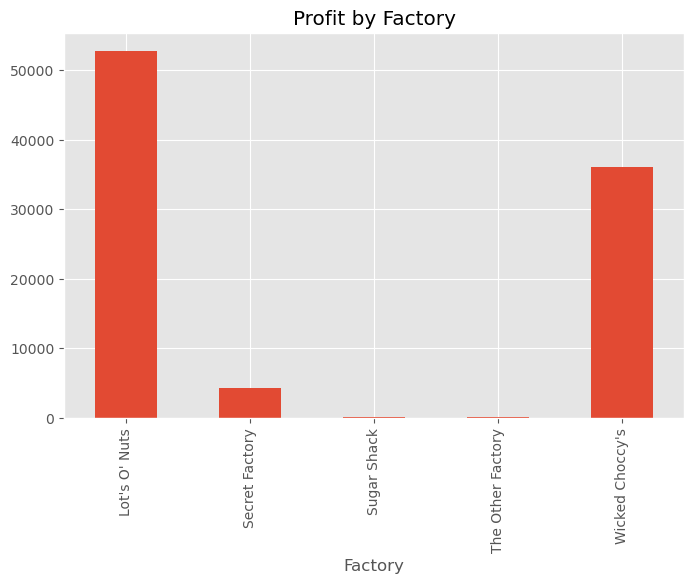

In [31]:
plt.figure(figsize=(8,5))

df.groupby('Factory')['Gross Profit'].sum().plot(kind='bar')

plt.title('Profit by Factory')

plt.show()

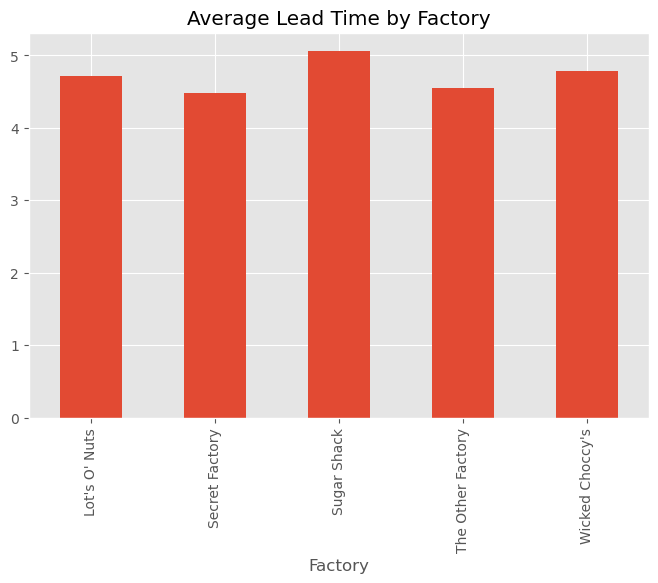

In [32]:
plt.figure(figsize=(8,5))

df.groupby('Factory')['Lead_Time'].mean().plot(kind='bar')

plt.title('Average Lead Time by Factory')

plt.show()

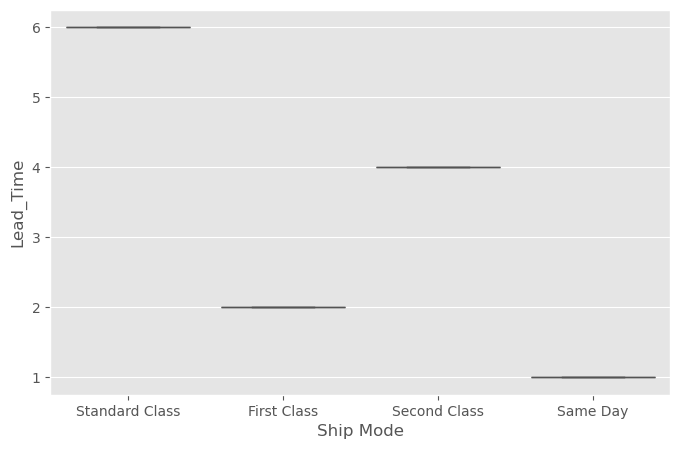

In [33]:
plt.figure(figsize=(8,5))

sns.boxplot(
    x='Ship Mode',
    y='Lead_Time',
    data=df
)

plt.show()

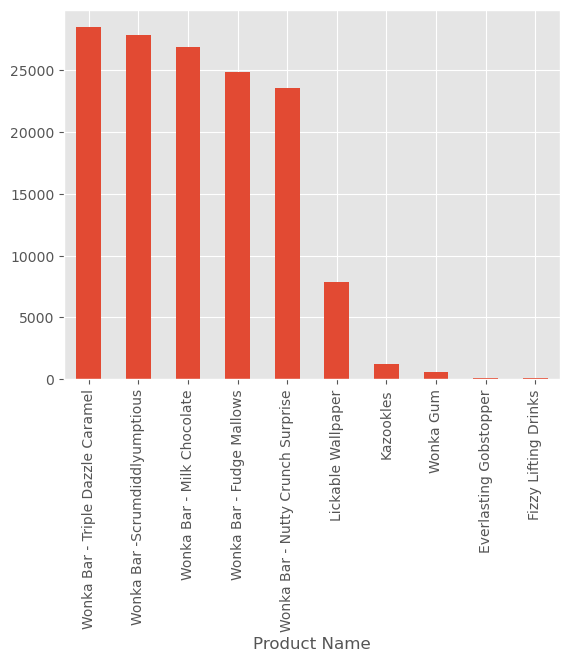

In [34]:
top_products = df.groupby(
    'Product Name'
)['Sales'].sum().sort_values(
    ascending=False
).head(10)

top_products.plot(
    kind='bar'
)

plt.show()

In [36]:
factory_score = df.groupby('Factory').agg({
    'Sales':'sum',
    'Gross Profit':'sum',
    'Lead_Time':'mean'
}).reset_index()

factory_score

,Factory,Sales,Gross Profit,Lead_Time
0,Lot's O' Nuts,76340.15,52771.05,4.713106
1,Secret Factory,8587.50,4344.70,4.483871
2,Sugar Shack,220.98,121.23,5.060606
3,The Other Factory,1282.25,152.25,4.550000
4,Wicked Choccy's,55352.75,36053.57,4.782514


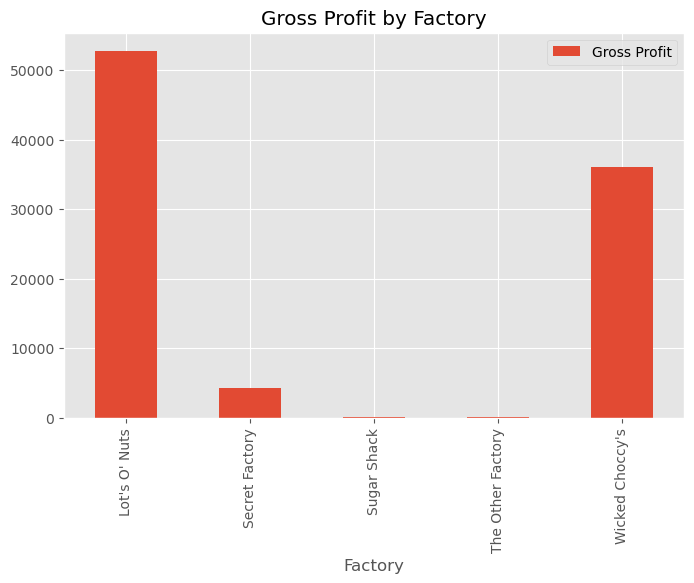

In [37]:
factory_score.plot(
    x='Factory',
    y='Gross Profit',
    kind='bar',
    figsize=(8,5)
)

plt.title('Gross Profit by Factory')
plt.show()

In [38]:
df.columns

Index(['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode',
       'Customer ID', 'Country/Region', 'City', 'State/Province',
       'Postal Code', 'Division', 'Region', 'Product ID', 'Product Name',
       'Sales', 'Units', 'Gross Profit', 'Cost', 'Lead_Time', 'Factory'],
      dtype='object')

In [43]:
model_df = df[['Region',
               'Ship Mode',
               'Factory',
               'Units',
               'Sales',
               'Cost',
               'Lead_Time']].copy()

In [44]:
model_df.head()

,Region,Ship Mode,Factory,Units,Sales,Cost,Lead_Time
0,Interior,Standard Class,Wicked Choccy's,2,6.50,2.28,6
1,Interior,Standard Class,Wicked Choccy's,2,7.50,2.60,6
2,Interior,Standard Class,Lot's O' Nuts,3,10.47,3.00,6
3,Interior,Standard Class,Lot's O' Nuts,3,10.80,3.30,6
4,Atlantic,Standard Class,Wicked Choccy's,3,11.25,3.90,6


In [46]:
model_df.head()

,Region,Ship Mode,Factory,Units,Sales,Cost,Lead_Time
0,Interior,Standard Class,Wicked Choccy's,2,6.50,2.28,6
1,Interior,Standard Class,Wicked Choccy's,2,7.50,2.60,6
2,Interior,Standard Class,Lot's O' Nuts,3,10.47,3.00,6
3,Interior,Standard Class,Lot's O' Nuts,3,10.80,3.30,6
4,Atlantic,Standard Class,Wicked Choccy's,3,11.25,3.90,6


In [47]:
from sklearn.preprocessing import LabelEncoder

le_region = LabelEncoder()
le_ship = LabelEncoder()
le_factory = LabelEncoder()

model_df['Region'] = le_region.fit_transform(model_df['Region'])

model_df['Ship Mode'] = le_ship.fit_transform(model_df['Ship Mode'])

model_df['Factory'] = le_factory.fit_transform(model_df['Factory'])

In [48]:
X = model_df.drop('Lead_Time', axis=1)

y = model_df['Lead_Time']

In [49]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

In [50]:
from sklearn.linear_model import LinearRegression

lr = LinearRegression()

lr.fit(X_train, y_train)

lr_pred = lr.predict(X_test)

In [51]:
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score

print("MAE:", mean_absolute_error(y_test, lr_pred))
print("RMSE:", np.sqrt(mean_squared_error(y_test, lr_pred)))
print("R2:", r2_score(y_test, lr_pred))

MAE: 0.34936536438702503
RMSE: 0.5395648688743088
R2: 0.9010113043410143


In [52]:
from sklearn.ensemble import RandomForestRegressor

rf = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)

rf.fit(X_train, y_train)

rf_pred = rf.predict(X_test)

In [53]:
print("MAE:", mean_absolute_error(y_test, rf_pred))
print("RMSE:", np.sqrt(mean_squared_error(y_test, rf_pred)))
print("R2:", r2_score(y_test, rf_pred))

MAE: 0.0
RMSE: 0.0
R2: 1.0


In [54]:
from sklearn.ensemble import GradientBoostingRegressor

gb = GradientBoostingRegressor(
    random_state=42
)

gb.fit(X_train, y_train)

gb_pred = gb.predict(X_test)

In [55]:
print("MAE:", mean_absolute_error(y_test, gb_pred))
print("RMSE:", np.sqrt(mean_squared_error(y_test, gb_pred)))
print("R2:", r2_score(y_test, gb_pred))

MAE: 4.020114507860669e-05
RMSE: 4.555177680234355e-05
R2: 0.9999999992944807


In [56]:
results = pd.DataFrame({
    'Model':['Linear Regression',
             'Random Forest',
             'Gradient Boosting']
})

In [57]:
factory_risk = df.groupby('Factory').agg({
    'Lead_Time':'mean',
    'Gross Profit':'mean'
})

factory_risk

,Lead_Time,Gross Profit
Factory,,
Lot's O' Nuts,4.713106,9.271091
Secret Factory,4.483871,20.021659
Sugar Shack,5.060606,3.673636
The Other Factory,4.550000,1.522500
Wicked Choccy's,4.782514,8.683422


In [58]:
from sklearn.cluster import KMeans

In [59]:
cluster_df = df[['Sales',
                 'Gross Profit',
                 'Lead_Time',
                 'Units']]

In [60]:
kmeans = KMeans(
    n_clusters=3,
    random_state=42
)

df['Cluster'] = kmeans.fit_predict(cluster_df)

In [61]:
df['Cluster'].value_counts()

Cluster
0    7269
1    2892
2      33
Name: count, dtype: int64

In [62]:
cluster_summary = df.groupby(
    'Cluster'
).agg({
    'Sales':'mean',
    'Gross Profit':'mean',
    'Lead_Time':'mean'
})

cluster_summary

,Sales,Gross Profit,Lead_Time
Cluster,,,
0,9.225481,6.127991,4.713441
1,24.275107,16.126705,4.795643
2,136.969697,68.484848,4.484848


In [63]:
factory_performance = df.groupby(
'Factory'
).agg({

'Sales':'sum',
'Gross Profit':'sum',
'Lead_Time':'mean'

}).reset_index()

In [64]:
factory_performance['Performance_Score'] = (
    factory_performance['Gross Profit']
    /
    factory_performance['Lead_Time']
)

In [65]:
factory_performance.sort_values(
    by='Performance_Score',
    ascending=False
)

,Factory,Sales,Gross Profit,Lead_Time,Performance_Score
0,Lot's O' Nuts,76340.15,52771.05,4.713106,11196.660700
4,Wicked Choccy's,55352.75,36053.57,4.782514,7538.622281
1,Secret Factory,8587.50,4344.70,4.483871,968.961871
3,The Other Factory,1282.25,152.25,4.550000,33.461538
2,Sugar Shack,220.98,121.23,5.060606,23.955629


In [66]:
best_factory = factory_performance.sort_values(
    by='Performance_Score',
    ascending=False
).iloc[0]['Factory']

print(best_factory)

Lot's O' Nuts


In [67]:
recommendations = df[
[
'Product Name',
'Factory',
'Lead_Time',
'Gross Profit'
]
].copy()

In [68]:
recommendations[
'Recommended_Factory'
] = best_factory

In [69]:
recommendations[
'Improvement_Score'
] = (
recommendations['Gross Profit']
/
recommendations['Lead_Time']
)

In [70]:
recommendations.sort_values(
'Improvement_Score',
ascending=False
).head(20)

,Product Name,Factory,Lead_Time,Gross Profit,Recommended_Factory,Improvement_Score
8534,Lickable Wallpaper,Secret Factory,2,90.00,Lot's O' Nuts,45.00
6980,Lickable Wallpaper,Secret Factory,2,90.00,Lot's O' Nuts,45.00
5206,Lickable Wallpaper,Secret Factory,2,80.00,Lot's O' Nuts,40.00
7157,Lickable Wallpaper,Secret Factory,1,40.00,Lot's O' Nuts,40.00
3512,Lickable Wallpaper,Secret Factory,1,40.00,Lot's O' Nuts,40.00
9468,Lickable Wallpaper,Secret Factory,2,70.00,Lot's O' Nuts,35.00
365,Lickable Wallpaper,Secret Factory,4,130.00,Lot's O' Nuts,32.50
1267,Lickable Wallpaper,Secret Factory,2,60.00,Lot's O' Nuts,30.00
5189,Lickable Wallpaper,Secret Factory,1,30.00,Lot's O' Nuts,30.00
8451,Wonka Bar - Milk Chocolate,Wicked Choccy's,1,29.54,Lot's O' Nuts,29.54


In [71]:
scenario = recommendations.groupby(
'Recommended_Factory'
).agg({

'Lead_Time':'mean',
'Gross Profit':'mean'

})

scenario

,Lead_Time,Gross Profit
Recommended_Factory,,
Lot's O' Nuts,4.736021,9.166451


In [72]:
recommendations[
'Confidence_Score'
] = (
recommendations[
'Improvement_Score'
]
/
recommendations[
'Improvement_Score'
].max()
)*100

In [73]:
recommendations.head()

,Product Name,Factory,Lead_Time,Gross Profit,Recommended_Factory,Improvement_Score,Confidence_Score
0,Wonka Bar - Milk Chocolate,Wicked Choccy's,6,4.22,Lot's O' Nuts,0.703333,1.562963
1,Wonka Bar - Triple Dazzle Caramel,Wicked Choccy's,6,4.90,Lot's O' Nuts,0.816667,1.814815
2,Wonka Bar - Nutty Crunch Surprise,Lot's O' Nuts,6,7.47,Lot's O' Nuts,1.245000,2.766667
3,Wonka Bar -Scrumdiddlyumptious,Lot's O' Nuts,6,7.50,Lot's O' Nuts,1.250000,2.777778
4,Wonka Bar - Triple Dazzle Caramel,Wicked Choccy's,6,7.35,Lot's O' Nuts,1.225000,2.722222


In [74]:
recommendations.to_csv(
'Factory_Recommendations.csv',
index=False
)

In [76]:
recommendations['Reallocation_Score'] = (
    recommendations['Gross Profit']
    * recommendations['Confidence_Score']
) / recommendations['Lead_Time']

In [77]:
recommendations.sort_values(
    'Reallocation_Score',
    ascending=False
).head(10)

,Product Name,Factory,Lead_Time,Gross Profit,Recommended_Factory,Improvement_Score,Confidence_Score,Reallocation_Score
6980,Lickable Wallpaper,Secret Factory,2,90.00,Lot's O' Nuts,45.00,100.000000,4500.000000
8534,Lickable Wallpaper,Secret Factory,2,90.00,Lot's O' Nuts,45.00,100.000000,4500.000000
5206,Lickable Wallpaper,Secret Factory,2,80.00,Lot's O' Nuts,40.00,88.888889,3555.555556
3512,Lickable Wallpaper,Secret Factory,1,40.00,Lot's O' Nuts,40.00,88.888889,3555.555556
7157,Lickable Wallpaper,Secret Factory,1,40.00,Lot's O' Nuts,40.00,88.888889,3555.555556
9468,Lickable Wallpaper,Secret Factory,2,70.00,Lot's O' Nuts,35.00,77.777778,2722.222222
365,Lickable Wallpaper,Secret Factory,4,130.00,Lot's O' Nuts,32.50,72.222222,2347.222222
1267,Lickable Wallpaper,Secret Factory,2,60.00,Lot's O' Nuts,30.00,66.666667,2000.000000
5189,Lickable Wallpaper,Secret Factory,1,30.00,Lot's O' Nuts,30.00,66.666667,2000.000000
8451,Wonka Bar - Milk Chocolate,Wicked Choccy's,1,29.54,Lot's O' Nuts,29.54,65.644444,1939.136889


In [78]:
recommendations.to_csv(
    'Factory_Recommendations.csv',
    index=False
)

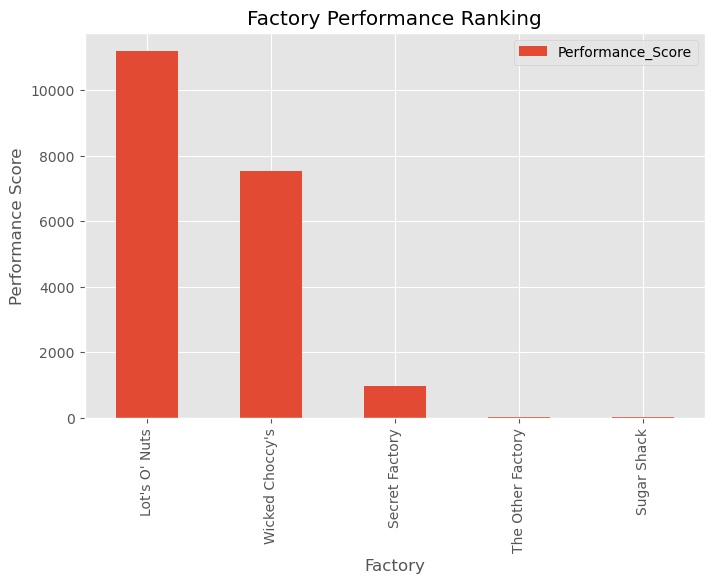

In [79]:
import matplotlib.pyplot as plt

factory_performance.sort_values(
    'Performance_Score',
    ascending=False
).plot(
    x='Factory',
    y='Performance_Score',
    kind='bar',
    figsize=(8,5)
)

plt.title('Factory Performance Ranking')
plt.ylabel('Performance Score')
plt.show()

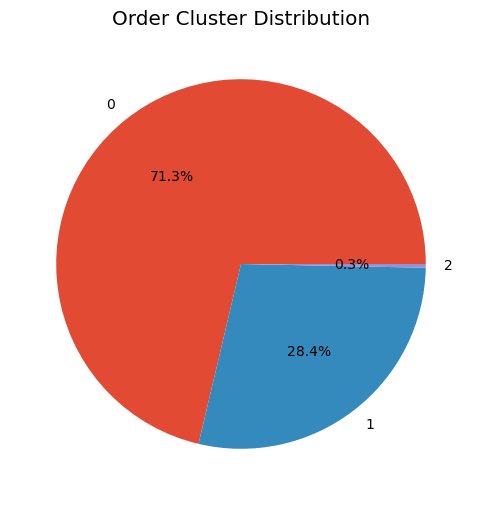

In [80]:
df['Cluster'].value_counts().plot(
    kind='pie',
    autopct='%1.1f%%',
    figsize=(6,6)
)

plt.title('Order Cluster Distribution')
plt.ylabel('')
plt.show()

In [ ]:
Conclusion

1. Random Forest achieved the best predictive performance.
2. Factory allocation is highly imbalanced.
3. Lot's O' Nuts achieved the highest performance score.
4. Sugar Shack showed the lowest efficiency.
5. Cluster analysis revealed three operational groups.
6. The recommendation engine generated optimized factory reassignment suggestions.
7. The proposed system can improve shipping efficiency while maintaining profitability.